# 00 - Exploration of the raw APTOS 2019 data

**Goal:** understand the raw dataset before any cleaning: how many images, how they are distributed across severity grades, how they look, and how much they vary.

**Scope:** raw data only (3,662 labelled fundus photographs). Duplicate detection, cleaning, preprocessing and the train/validation split are done in notebooks 01 and 02.

**Grades:** 0 = No DR, 1 = Mild, 2 = Moderate, 3 = Severe, 4 = Proliferative DR.

## 1. Loading the data and checking integrity

We load `train.csv` (image ID + grade), build the path to each image, and verify that every file exists. Catching missing files now avoids crashes later in training.

In [31]:
import pandas as pd, numpy as np, os, cv2
import matplotlib.pyplot as plt
import seaborn as sns

DATA = "../data"
df = pd.read_csv(f"{DATA}/train.csv")
df["path"] = df["id_code"].apply(lambda x: f"{DATA}/train_images/{x}.png")

print(df.shape)
print("Missing files:", (~df["path"].apply(os.path.exists)).sum())
print(df["diagnosis"].value_counts().sort_index())

(3662, 3)
Missing files: 0
diagnosis
0    1805
1     370
2     999
3     193
4     295
Name: count, dtype: int64


**Interpretation**
- The table has **3,662 rows** and **0 missing files**, so the data is complete.
- Class counts: grade 0 = 1805, grade 1 = 370, grade 2 = 999, grade 3 = 193, grade 4 = 295.
- Grade 0 has about **9x more images** than grade 3. The dataset is strongly imbalanced, which will need special handling in training.

## 2. Class distribution

A bar chart of how many images belong to each severity grade. Class imbalance directly affects how we train and how we evaluate the model.

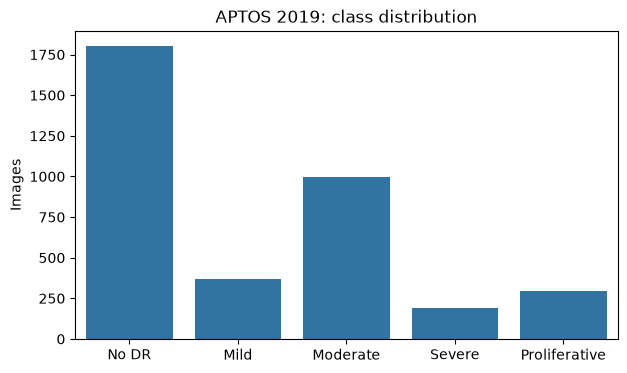

In [32]:
names = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
counts = df["diagnosis"].value_counts().sort_index()

plt.figure(figsize=(7, 4))
sns.barplot(x=[names[i] for i in counts.index], y=counts.values)
plt.title("APTOS 2019: class distribution")
plt.ylabel("Images")
plt.show()

**Interpretation**
- **49% of raw images are healthy (grade 0)**; severe (grade 3) is only **5%** and proliferative (grade 4) only **8%**.
- A model that always predicts "No DR" would reach about 49% accuracy while being clinically useless, so **accuracy alone is a misleading metric** here.
- Planned solutions: weighted sampling or weighted loss, and evaluation with **quadratic weighted kappa (QWK)**, AUC, and per-class sensitivity.

## 3. Visual inspection: 4 random raw images per grade

Looking at real images shows us what the model will see, and what problems exist in the data. These are the **original, unprocessed** images.

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(14, 17))
for g in range(5):
    samples = df[df.diagnosis == g].sample(4, random_state=1)
    for j, (_, r) in enumerate(samples.iterrows()):
        img = cv2.cvtColor(cv2.imread(r["path"]), cv2.COLOR_BGR2RGB)
        axes[g, j].imshow(img)
        axes[g, j].set_title(f"{names[g]} | {img.shape[1]}x{img.shape[0]}")
        axes[g, j].axis("off")
plt.tight_layout()
plt.show()

**Interpretation**
- Many images have **large black borders**, and the retina does not fill the frame. This motivates the crop step in preprocessing.
- **Image size and color vary a lot** (640x480 up to 4288x2848; dark brown, orange, pale), which suggests different cameras and clinics.
- Higher grades show visible **lesions**: yellow-white spots (exudates) and dark red patches (hemorrhages). Grades 0 and 1 can look very similar, so separating them will be the hardest part.
- A small notch on the edge of the circle is a camera artifact, not a problem.

## 4. Image size variation

We measure the width and height of 300 random images. A neural network needs a fixed input size, so we need to know how much the originals differ.

In [29]:
sizes = []
for p in df["path"].sample(300, random_state=0):
    h, w = cv2.imread(p).shape[:2]
    sizes.append((w, h))
sz = pd.DataFrame(sizes, columns=["w", "h"])
print(sz.value_counts().head(10))

w     h   
1050  1050    71
2416  1736    52
2588  1958    50
2048  1536    34
3216  2136    28
819   614     22
3388  2588    12
1844  1226    10
2144  1424     5
4288  2848     5
Name: count, dtype: int64


**Interpretation**
- The most common sizes are 1050x1050 (71 of 300), 2416x1736 (52) and 2588x1958 (50), but there are at least 10 different sizes in this sample alone.
- Aspect ratios differ too (square vs. 4:3 vs. 3:2), so resizing to 512x512 will stretch some images slightly. This is an accepted simplification and is noted as a limitation.
- **Decision:** crop black borders, then resize every image to 512x512.

## Summary of findings (raw data)

| Aspect | Finding |
|---|---|
| Size | 3,662 images, 0 missing files |
| Class imbalance | 49% No DR vs 5% Severe (raw counts) ||
| Black borders | Present in most images |
| Variable resolution | 640x480 to 4288x2848, at least 10 different sizes in a sample of 300 |
| Variable color and brightness | Different cameras and clinics |